# Wang et al. 2019 — Glioblastoma (10x) · 03 Signatures & Gate 2
Deliverable signature UMAPs (**raw** per-cell scores, as the reference shows) on the NATIVE embedding, and the
**Gate 2** decision. Gate 2 asks whether the embryonic module pattern is present — a Gast/pSom hub/gradient with
Crest as an opposing terminal readout. Read off the raw scores and a control-pool null (02), it is **absent**.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| raw scores present:', [m for m in modules if m in adata.obs])
print('global RAW module means:', {m: round(float(adata.obs[m].mean()),4) for m in ['Gast','pSom','Crest']})

cells: 9634 | raw scores present: ['Gast', 'pSom', 'Crest']
global RAW module means: {'Gast': -0.0025, 'pSom': 0.0077, 'Crest': -0.0073}


### Gate 2 evidence (raw scores + neutral-control correlations)

In [4]:
raw = adata.obs[['Gast','pSom','Crest']].values
print('union-pool RAW correlations : Gast-pSom %+.3f | Crest-Gast %+.3f | Crest-pSom %+.3f' % (
    np.corrcoef(raw[:,0],raw[:,1])[0,1], np.corrcoef(raw[:,2],raw[:,0])[0,1], np.corrcoef(raw[:,2],raw[:,1])[0,1]))
print('neutral-control RAW corr    : Gast-pSom %+.3f | Crest-Gast %+.3f | Crest-pSom %+.3f' % (
    np.corrcoef(adata.obs['Gast_d'],adata.obs['pSom_d'])[0,1],
    np.corrcoef(adata.obs['Crest_d'],adata.obs['Gast_d'])[0,1],
    np.corrcoef(adata.obs['Crest_d'],adata.obs['pSom_d'])[0,1]))
t = adata.obs['t'].values
print('\nRAW score vs pseudotime (Spearman):', {m: round(spearmanr(t, adata.obs[m])[0],3) for m in ['Gast','pSom','Crest']})
print('\nGATE 2 = NO-GO. Under a neutral control all three modules correlate POSITIVELY (no Crest opposition);')
print('the union-pool pSom<->Crest anti-correlation was a scoring artifact (02 null test). Raw modules are ~85% noise')
print('(spatial-structure ratio 0.12-0.15 vs 0.23-0.39 in the Neftel GBM GO reference) and near-flat across all lobes.')
print('The embryonic hub/arm/opposing-Crest geometry is ABSENT -> do not force a trajectory. Gate 3 = NA.')

union-pool RAW correlations : Gast-pSom -0.080 | Crest-Gast -0.414 | Crest-pSom -0.607
neutral-control RAW corr    : Gast-pSom +0.618 | Crest-Gast +0.465 | Crest-pSom +0.374

RAW score vs pseudotime (Spearman): {'Gast': np.float64(-0.026), 'pSom': np.float64(-0.156), 'Crest': np.float64(0.137)}

GATE 2 = NO-GO. Under a neutral control all three modules correlate POSITIVELY (no Crest opposition);
the union-pool pSom<->Crest anti-correlation was a scoring artifact (02 null test). Raw modules are ~85% noise
(spatial-structure ratio 0.12-0.15 vs 0.23-0.39 in the Neftel GBM GO reference) and near-flat across all lobes.
The embryonic hub/arm/opposing-Crest geometry is ABSENT -> do not force a trajectory. Gate 3 = NA.


### Deliverable signature figures (RAW scores, native embedding) + colorbars

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


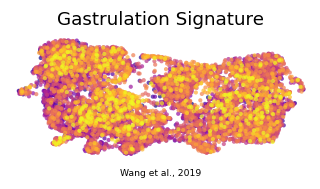

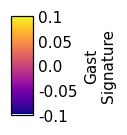

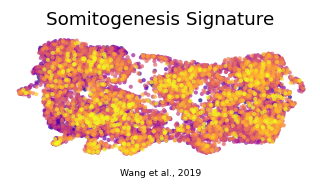

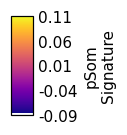

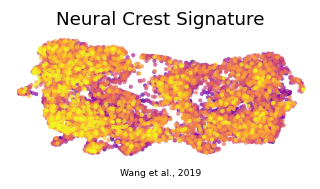

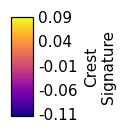

In [5]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    v = adata.obs[m].values; lo, hi = np.percentile(v, [2, 98])
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(adata, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None, frameon=False, show=False, ax=ax, title=titles[m], vmin=lo, vmax=hi)
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
    ax.text(.5, -.12, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show(); print('saved', f'{m}_signature.pdf', '+ colorbar')

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (9634, 26409)
